In [1]:
from pathlib import Path
import sys
# Add src to path for importing local modules
sys.path.insert(0, str(Path("../src").resolve()))
from data_io import load_assembled

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from trompy import save_figure_atomic
from extract_behav_parameters import smooth_array


from figure_config import (
    configure_matplotlib, COLORS, HEATMAP_CMAP_DIV,
    HEATMAP_CMAP_RED, HEATMAP_CMAP_BLUE,
    DATAFOLDER, FIGSFOLDER,
    SAVE_FIGS
)
from figure_plotting import (
    smooth_array, scale_vlim_to_data,
)

# Configure matplotlib
configure_matplotlib()
colors = COLORS  # Use shared color palette
custom_cmap_red = HEATMAP_CMAP_RED  # Use shared colormap
custom_cmap_blue = HEATMAP_CMAP_BLUE  # Use shared colormap

custom_cmap = HEATMAP_CMAP_DIV  # Use shared diverging colormap

SAVE_FIGS = True

In [2]:
assembled_data_path = DATAFOLDER / "assembled"

data = load_assembled(assembled_data_path)

# Extract main components
x_array = data["x_array"]
snips_photo = data["snips_photo"]
snips_simba = data["snips_simba"]

params = data.get("params", {})
metadata = data.get("metadata", {})

print("Loaded assembled data from data/assembled")
print(f"\nData structure:")
print(f"  - x_array shape: {x_array.shape}")
print(f"  - snips_photo shape: {snips_photo.shape}")
print(f"  - snips_simba shape: {snips_simba.shape}")
print(f"  - x_array columns: {x_array.columns.tolist()}")
print(f"  - Number of trials: {len(x_array)}")

Loaded assembled data from data/assembled

Data structure:
  - x_array shape: (1960, 17)
  - snips_photo shape: (1960, 200)
  - snips_simba shape: (1960, 200)
  - x_array columns: ['trial', 'id', 'condition', 'infusiontype', 'sex', 'simba_raw_mean', 'simba_zscore_mean', 'simba_median_balance', 'auc_snips', 'auc_snips_early', 'auc_snips_late', 'time_moving', 'time_moving_raw', 'realigned_trials_da', 'realigned_trials_da_velocity', 'realigned_trials_behav', 'trial_aligned']
  - Number of trials: 1960


In [3]:
snips_to_plot = np.array(smooth_array(snips_simba))
vlim_behav = (-1, 1)
vlim_photo = (-1, 1)
rats = x_array.query("infusiontype == '45NaCl'").id.unique()


def make_rep_rat_plot(snips_simba, snips_photo, x_array, rat):
    f, ax = plt.subplots(ncols=4, figsize=(7, 1.5),
                        gridspec_kw={"wspace": 0.6, "bottom": 0.35,
                                     "left": 0.05, "right": 0.95},)

    behav_data = snips_simba[x_array.query("id == @rat and condition == 'deplete'").index, :]
    photo_data = snips_photo[x_array.query("id == @rat and condition == 'deplete'").index, :]

    behav_auc = x_array.query("id == @rat and condition == 'deplete'").auc_simba.values


    hm = sns.heatmap(behav_data, ax=ax[0], cmap=custom_cmap,
                vmin=vlim_behav[0], vmax=vlim_behav[1],
                cbar=False
                )
    hm.collections[0].set_rasterized(True)
    ax[0].set_yticks([])
    ax[0].set_xticks([])

    ax[1].plot(gaussian_filter1d(np.mean(behav_data[:,50:150], axis=1), sigma=5), color=colors[3])
    ax[1].set_xlabel("Trial")
    ax[1].set_ylabel("AUC")
    sns.despine(ax=ax[1], offset=5)

    hm = sns.heatmap(photo_data, ax=ax[2], cmap=custom_cmap,
                vmin=vlim_photo[0], vmax=vlim_photo[1],
                cbar=False
                )
    hm.collections[0].set_rasterized(True)


    ax[3].plot(gaussian_filter1d(np.mean(photo_data[:,50:150], axis=1), sigma=5), color=colors[3])



    for axis in [ax[0], ax[2]]:
        axis.set_yticks([])
        axis.set_xticks([])
        axis.set_ylabel("Trials")
        axis.plot((149, 198), (51, 51), color="k", linewidth=2, alpha=0.3, clip_on=False)
        axis.text(175, 53, "5 s", ha="center", va="top", fontsize=10, color="k")

    for axis in [ax[1], ax[3]]:
        axis.axhline(0, color="gray", linestyle="--", linewidth=1)
        axis.set_xlabel("Trial")
        axis.set_ylabel("AUC")
        sns.despine(ax=axis, offset=5)

    return f

In [4]:
def norm_signal(y, smooth=True):
    if smooth:
        y = gaussian_filter1d(y, sigma=1)
    
    ymin, ymax = y.min(), y.max()
    
    return (
        (y - ymin) / (ymax - ymin)
        if ymax > ymin
        else np.ones_like(y) * 0.5
        )

Rat PB26 behav transition: 29; DA transition: 23


Rat PB27 behav transition: 47; DA transition: 29


Rat PB30 behav transition: 28; DA transition: 15


Rat PB31 behav transition: 17; DA transition: 18


Rat PB46 behav transition: 9; DA transition: 4


Rat PB48 behav transition: 24; DA transition: 23


Rat PB71 behav transition: 22; DA transition: 15


Rat PB72 behav transition: 13; DA transition: 9


Rat PB73 behav transition: 21; DA transition: 18


Rat PB75 behav transition: 31; DA transition: 31


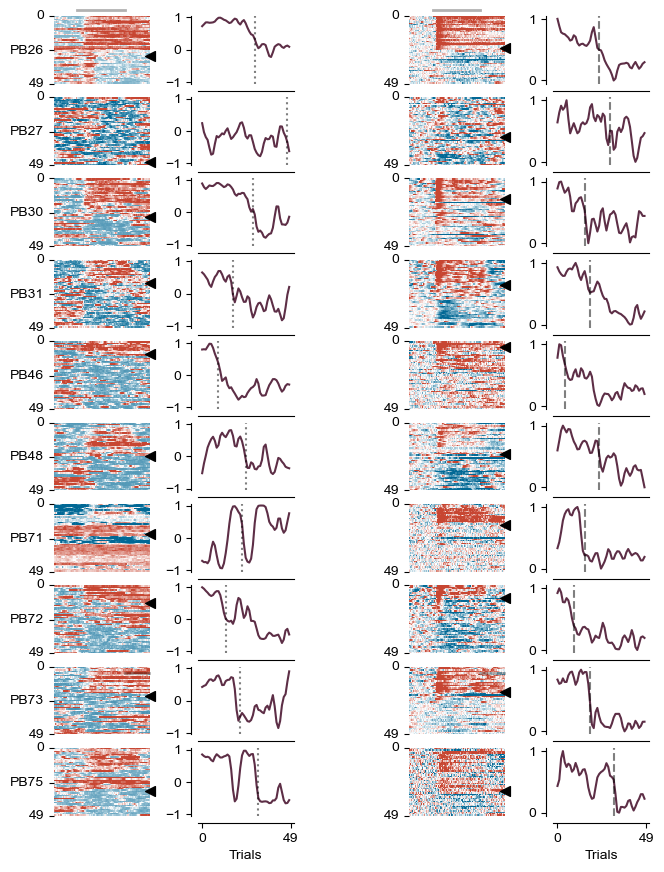

In [5]:
snips_to_plot = np.array(smooth_array(snips_simba))
vlim_behav = (-1, 1)
vlim_photo = (-1, 1)
rats = x_array.query("infusiontype == '45NaCl'").id.unique()

f, ax = plt.subplots(ncols=5, nrows=len(rats), figsize=(7,10),
                     gridspec_kw={"width_ratios": [1, 1, 0.2, 1, 1],
                                  "wspace": 0.6, "bottom": 0.15, "top": 0.95,
                                  "left": 0.1, "right": 0.95},
                                  )    



for idx, rat in enumerate(rats[:]):
    behav_data = snips_simba[x_array.query("id == @rat and condition == 'deplete'").index, :]
    photo_data = snips_photo[x_array.query("id == @rat and condition == 'deplete'").index, :]

    simba_median = x_array.query("id == @rat and condition == 'deplete'").simba_median_balance.values
    auc_da = x_array.query("id == @rat and condition == 'deplete'").auc_snips.values
    da_norm = norm_signal(auc_da, smooth=True)
    
    behav_transition = x_array.query("id == @rat and condition == 'deplete' and realigned_trials_behav == 0").trial.values[0]
    da_transition = x_array.query("id == @rat and condition == 'deplete' and realigned_trials_da == 0").trial.values[0]
    print(f"Rat {rat} behav transition: {behav_transition}; DA transition: {da_transition}")

    vlim_behav = scale_vlim_to_data(behav_data, percentile=90)
    vlim_photo = scale_vlim_to_data(photo_data, percentile=90)

    hm = sns.heatmap(behav_data, ax=ax[idx, 0], cmap=custom_cmap,
                    vmin=vlim_behav[0], vmax=vlim_behav[1],
                    cbar=False
                    )
    hm.collections[0].set_rasterized(True)
    ax[idx, 0].set_yticks([0, 25, 49], labels=["0", rat, "49"], rotation=0)
    ax[idx, 0].set_xticks([])
    ax[idx, 0].scatter(200, behav_transition, color="k", marker="<", s=50, zorder=5, clip_on=False)


    ax[idx, 1].plot(gaussian_filter1d(simba_median, sigma=1), color=colors[3])
    ax[idx, 1].set_ylim(-1.05, 1.05)
    ax[idx, 1].axvline(behav_transition, color="k", linestyle=":", alpha=0.5)

    hm = sns.heatmap(photo_data, ax=ax[idx, 3], cmap=custom_cmap,
                vmin=vlim_photo[0], vmax=vlim_photo[1],
                cbar=False
                )
    hm.collections[0].set_rasterized(True)
    ax[idx, 3].set_yticks([0, 49], labels=["0", "49"], rotation=0)
    ax[idx, 3].set_xticks([])
    ax[idx, 3].scatter(200, da_transition, color="k", marker="<", s=50, zorder=5, clip_on=False)

    ax[idx, 4].plot(da_norm, color=colors[3])
    ax[idx, 4].axvline(da_transition, color="k", linestyle="--", alpha=0.5)

    for axis in [ax[idx, 1], ax[idx, 4]]:
        sns.despine(ax=axis, offset=5)
        axis.set_xticks([])

    ax[idx, 2].axis("off")

ax[0, 0].plot((49, 148), (-4, -4), color="k", linewidth=2, alpha=0.3, clip_on=False)
ax[0, 3].plot((49, 148), (-4, -4), color="k", linewidth=2, alpha=0.3, clip_on=False)

ax[9, 0].plot((149, 198), (-54, -54), color="k", linewidth=2, alpha=0.3, clip_on=False)
ax[9, 3].plot((149, 198), (-54, -54), color="k", linewidth=2, alpha=0.3, clip_on=False)

ax[9, 1].set_xticks([0,49])
ax[9, 4].set_xticks([0,49])
ax[9, 1].set_xlabel("Trials")
ax[9, 4].set_xlabel("Trials")

if SAVE_FIGS:
    save_figure_atomic(f, "figS4_individual_rats", FIGSFOLDER)

